In [3]:
import csv 
import numpy as np 
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

In [4]:

def read_data_from_csv(filename):
    t_log = []
    energy_log = []
    charged_nodes_positions_log = []
    with open(filename, mode='r') as file:
        reader = csv.reader(file)
        headings = next(reader)  
        for row in reader:
            t_log.append(float(row[0]))
            energy_log.append(float(row[1]))
            num_charges = (len(row) - 2) // 2
            charged_positions = []
            for i in range(num_charges):
                x = float(row[2 + 2*i])
                y = float(row[3 + 2*i])
                charged_positions.append((x, y))
            charged_nodes_positions_log.append(charged_positions)
    return t_log, energy_log, charged_nodes_positions_log

Time of maximum energy minimum: 24.0, Energy at that time: 0.018969859399074664
Times of energy maxima: [14.], Energies at those times: [6.73447275]


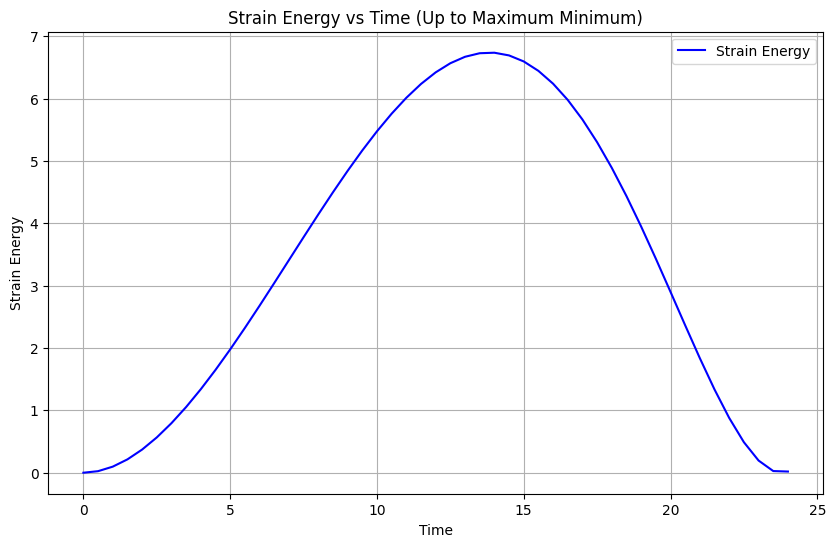

In [5]:
t_log, energy_log, charged_nodes_positions_log = read_data_from_csv("charge_distance_data.csv")
t_log = np.array(t_log)
energy_log = np.array(energy_log)


minima_indices, _ = find_peaks([-e for e in energy_log])
max_idx = minima_indices[np.argmax(t_log[minima_indices])]
print(f"Time of maximum energy minimum: {t_log[max_idx]}, Energy at that time: {energy_log[max_idx]}")
t_log_filtered = t_log[:max_idx+1]
energy_log_filtered = energy_log[:max_idx+1]

maxima_indices, _ = find_peaks(energy_log_filtered)
print(f"Times of energy maxima: {t_log_filtered[maxima_indices]}, Energies at those times: {energy_log_filtered[maxima_indices]}")

plt.figure(figsize=(10, 6))
plt.plot(t_log_filtered, energy_log_filtered, label='Strain Energy', color='blue')
plt.title('Strain Energy vs Time (Up to Maximum Minimum)')
plt.xlabel('Time')
plt.ylabel('Strain Energy')
plt.grid()
plt.legend()
plt.show()

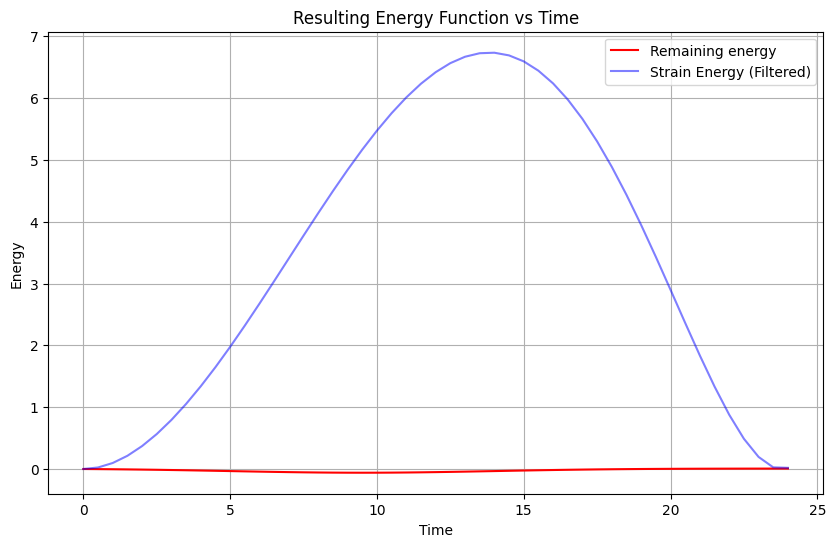

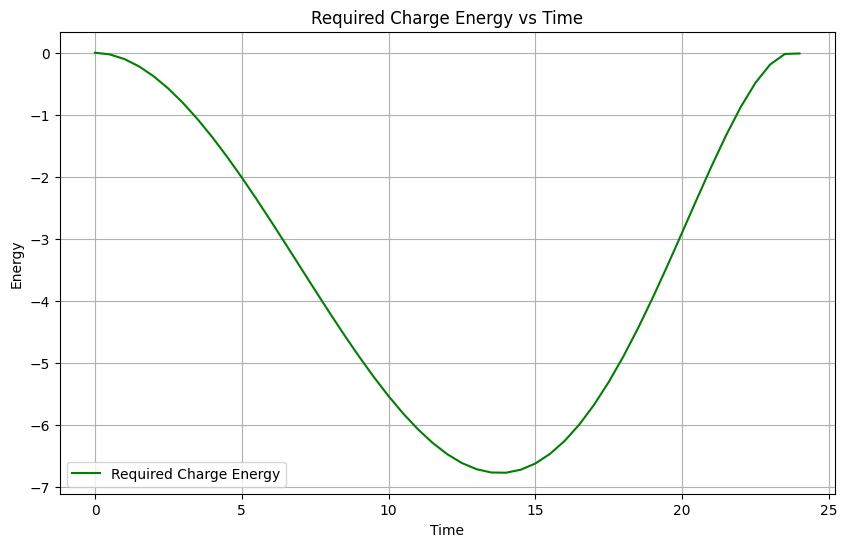

In [20]:
α = int((max_idx)*1.5)
β = t_log[int(maxima_indices[0]*0.7)]
σ = 0.1*np.abs(α-β)
# print(f"α : {t_log[α]}, β : {t_log[β]}")
# a = (β/(α-β))*np.exp((-1/(2*σ*σ))*(2*β*α - α*α))
a = np.max(energy_log_filtered) * 0.01

def gaussian(t, μ, σ, a):
    return a * np.exp(-((t - μ) / σ) ** 2)



def resulting_energy_function_non_interacting(t, β, σ, a):
    val =  -gaussian(t, μ=β, σ=σ, a=a) + gaussian(0, μ=β, σ=σ, a=a)
    return val

# Plotting the final energy function
# t_values = np.linspace(0, t_log_filtered[-1], 1000)
final_energy_values = resulting_energy_function_non_interacting(t_log_filtered, β=β, σ=σ, a=a)
plt.figure(figsize=(10, 6))
plt.plot(t_log_filtered, final_energy_values, label='Remaining energy', color='red')
plt.plot(t_log_filtered, energy_log_filtered, label='Strain Energy (Filtered)', color='blue', alpha=0.5)
plt.title('Resulting Energy Function vs Time')
plt.xlabel('Time')
plt.ylabel('Energy')
plt.grid()
plt.legend()
plt.show()

required_charge_energy_values = final_energy_values-energy_log_filtered
#Plot the sum of the two functions
plt.figure(figsize=(10, 6))
plt.plot(t_log_filtered, required_charge_energy_values, label='Required Charge Energy', color='green')
plt.title('Required Charge Energy vs Time')
plt.xlabel('Time')
plt.ylabel('Energy')
plt.grid()
plt.legend()
plt.show()
    

In [21]:
print(f"Shape of charged_nodes_positions_log: {len(charged_nodes_positions_log)}, {len(charged_nodes_positions_log[0])}, {len(charged_nodes_positions_log[0][0])}")
charged_nodes_positions_log = np.array(charged_nodes_positions_log)
def Kijk(pos: np.ndarray, i: int, j: int, t: int):
    distance = np.linalg.norm(pos[i] - pos[j])
    return 1/distance if distance != 0 else 0


Shape of charged_nodes_positions_log: 57, 64, 2


In [8]:
num_charges = charged_nodes_positions_log.shape[1]
import numpy as np

def compute_A_all(positions: np.ndarray):
    """
    positions shape: (T, N, dim)
    """
    T, N, _ = positions.shape
    A_all = np.zeros((T, N, N))

    for t in range(T):
        pos = positions[t]

        diff = pos[:, None, :] - pos[None, :, :]
        dist = np.linalg.norm(diff, axis=2)

        with np.errstate(divide='ignore', invalid='ignore'):
            A = np.where(dist > 0, 1.0 / dist, 0.0)
        np.fill_diagonal(A, 0.0)
        A_all[t] = A
    return A_all

In [9]:
def energy(q, A):
    return 0.5 * q @ A @ q
def energy_time_series(q, A_all):
    return np.array([energy(q, A) for A in A_all])
def objective(q, A_all, U_target):
    U_pred = energy_time_series(q, A_all)
    diff = U_pred - U_target
    return np.sum(diff**2)
def gradient(q, A_all, U_target):
    grad = np.zeros_like(q)

    for t, A in enumerate(A_all):
        U = 0.5 * q @ A @ q
        diff = U - U_target[t]

        grad += 2 * diff * (A @ q)

    return grad

In [10]:
from scipy.optimize import minimize

def solve_charges(positions, U_target):

    A_all = compute_A_all(positions)

    N = positions.shape[1]

    q0 = np.random.randn(N)

    result = minimize(
        fun=objective,
        x0=q0,
        args=(A_all, U_target),
        jac=gradient,
        method='L-BFGS-B'
    )

    return result.x, result

In [11]:
charges, result = solve_charges(
    positions=charged_nodes_positions_log[:len(required_charge_energy_values)],
    U_target=required_charge_energy_values
)

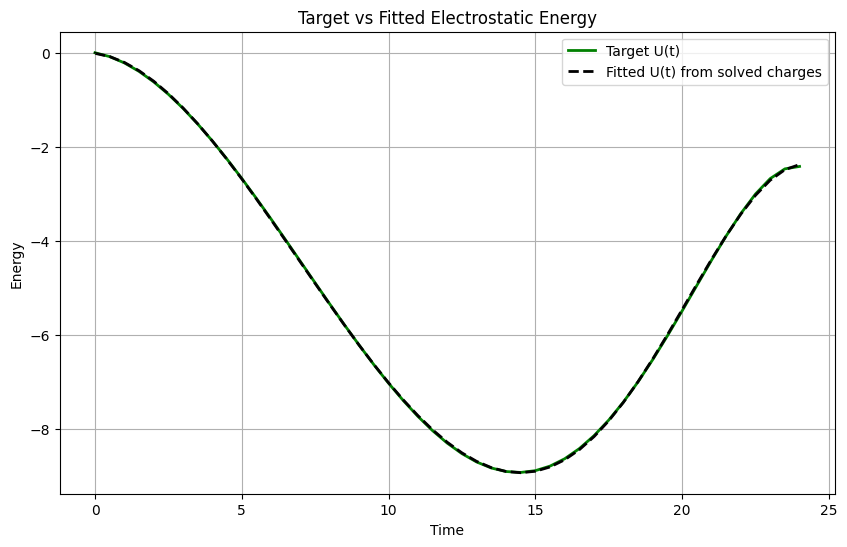

In [12]:
# Compare target energy vs fitted-charge energy on the same time window
positions_fit = charged_nodes_positions_log[:len(required_charge_energy_values)]
A_all_fit = compute_A_all(positions_fit)
U_fit = energy_time_series(charges, A_all_fit)

t_fit = t_log_filtered[:len(required_charge_energy_values)]

plt.figure(figsize=(10, 6))
plt.plot(t_fit, required_charge_energy_values, label='Target U(t)', color='green', linewidth=2)
plt.plot(t_fit, U_fit, label='Fitted U(t) from solved charges', color='black', linestyle='--', linewidth=2)
plt.title('Target vs Fitted Electrostatic Energy')
plt.xlabel('Time')
plt.ylabel('Energy')
plt.grid(True)
plt.legend()
plt.show()

Charge Vector Statistics:
     count: 500
      mean: 0.00308208
       std: 0.997747
       min: -3.02156
       25%: -0.654815
    median: -0.0180593
       75%: 0.726694
       max: 3.47416
  mean_abs: 0.792154
   l2_norm: 22.3104


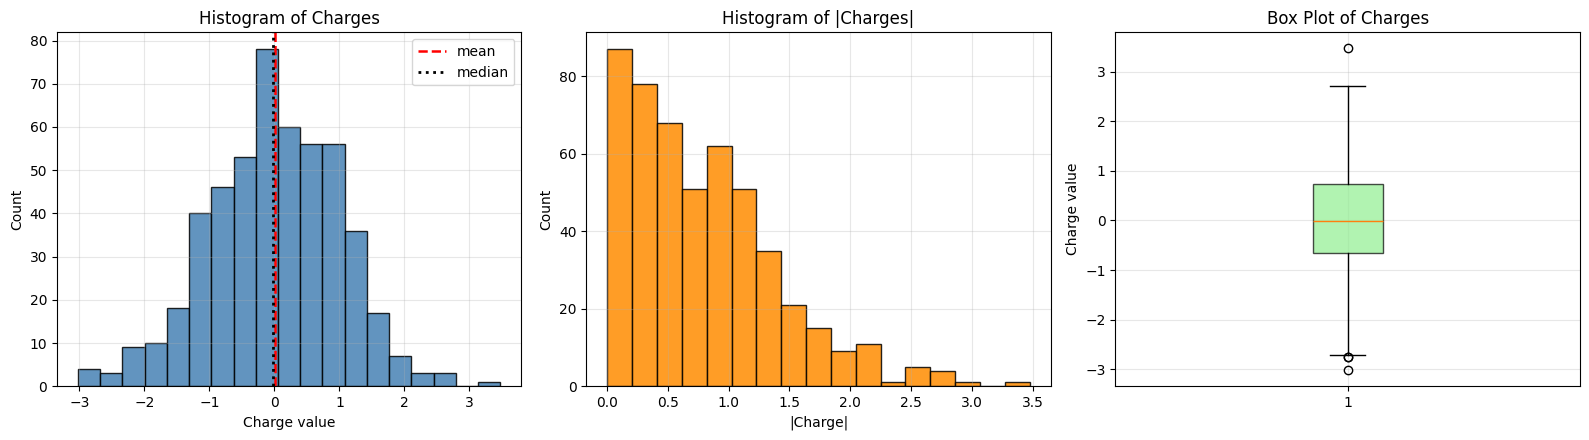

In [161]:
# Statistics and distribution plots for the solved charge vector
q = np.asarray(charges, dtype=float)

stats = {
    'count': q.size,
    'mean': np.mean(q),
    'std': np.std(q),
    'min': np.min(q),
    '25%': np.percentile(q, 25),
    'median': np.median(q),
    '75%': np.percentile(q, 75),
    'max': np.max(q),
    'mean_abs': np.mean(np.abs(q)),
    'l2_norm': np.linalg.norm(q),
}

print('Charge Vector Statistics:')
for k, v in stats.items():
    if isinstance(v, (int, np.integer)):
        print(f'  {k:>8}: {v}')
    else:
        print(f'  {k:>8}: {v:.6g}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].hist(q, bins='auto', color='steelblue', edgecolor='black', alpha=0.85)
axes[0].axvline(stats['mean'], color='red', linestyle='--', linewidth=1.8, label='mean')
axes[0].axvline(stats['median'], color='black', linestyle=':', linewidth=2, label='median')
axes[0].set_title('Histogram of Charges')
axes[0].set_xlabel('Charge value')
axes[0].set_ylabel('Count')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].hist(np.abs(q), bins='auto', color='darkorange', edgecolor='black', alpha=0.85)
axes[1].set_title('Histogram of |Charges|')
axes[1].set_xlabel('|Charge|')
axes[1].set_ylabel('Count')
axes[1].grid(True, alpha=0.3)

axes[2].boxplot(q, vert=True, patch_artist=True, boxprops=dict(facecolor='lightgreen', alpha=0.7))
axes[2].set_title('Box Plot of Charges')
axes[2].set_ylabel('Charge value')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()